# What does one grid cell holding an entire war look like?

**One UCDP event puts 113,368 deaths into a single 0.5&deg; cell in a single
month.** This notebook draws that, draws what it looks like once the event is
spread across the time and space UCDP actually declared, and checks that
nothing was invented or lost in between.

> **Evidence as of 2026-11-06**, against the consolidated UCDP store on this
> machine. Unlike `acled_cursor_parity.ipynb`, this notebook **does re-run**:
> every number below is recomputed from the store, and the three viewpoint
> builds are produced by the same `scripts/build_viewpoint.py` the pipeline
> uses. Re-running it on a newer store will shift the figures and should.

The defect is issue
[#533](https://github.com/views-platform/views-datafactory/issues/533); the
design it tests is in
`reports/2026-11-04_summary_event_allocation_dossier/11_allocator_spec.md`.

**Two findings in section 3 came out of writing this notebook and were not
known before it.** Production drops 43,933 events carrying 785,626 deaths
rather than placing them imprecisely, and the legacy splitter reports 96
deaths that appear in no version of the source. Both are measured below.

## 1. The event

UCDP event **463131** is the Tigray war, recorded as one row:

| field | value | what it means |
|---|---|---|
| `best` | 113,368 | fatalities |
| `date_start` / `date_end` | 2021-01-01 / 2021-12-31 | the whole year |
| `date_prec` | **5** | *"the date is known only to the year"* |
| `where_prec` | **5** | *"the location is known only to a group of regions"* |
| `where_description` | Tigray, Afar, Amhara | three Ethiopian regions |

Both precision codes are UCDP telling us what it does **not** know. Today's
pipeline reads neither: it places the event on its closing month and its
centroid cell, which asserts a precision the source explicitly disclaims.

It is not the only one. Event **463137** carries 121,848 deaths over
Aug&ndash;Oct 2022 under the same codes.

In [1]:
"""Pull the source event straight out of the consolidated store."""

from pathlib import Path

import pyarrow.parquet as pq

REPO = Path("..")
STORE = REPO / "data" / "consolidated" / "ucdp_store.parquet"

FIELDS = [
    "id", "best", "low", "high", "date_start", "date_end",
    "date_prec", "where_prec", "event_clarity", "where_description",
    "country", "priogrid_gid", "type_of_violence",
]

src = pq.read_table(STORE, columns=FIELDS).to_pandas().drop_duplicates("id")

for event_id in (463131, 463137):
    row = src[src.id == event_id].iloc[0]
    print(f"event {event_id}")
    for f in ("best", "date_start", "date_end", "date_prec",
              "where_prec", "event_clarity", "where_description", "country"):
        print(f"    {f:<20} {row[f]}")
    print()

event 463131
    best                 113368
    date_start           2021-01-01
    date_end             2021-12-31
    date_prec            5
    where_prec           5
    event_clarity        2
    where_description    Tigray, Afar, Amhara
    country              Ethiopia

event 463137
    best                 121848
    date_start           2022-08-24
    date_end             2022-10-24
    date_prec            5
    where_prec           5
    event_clarity        2
    where_description    None
    country              Ethiopia



## 2. Three builds of the same data

Each profile is a named, selectable configuration in
`src/datafactory_viewpoint/profiles.py`. They differ **only** in where a
summary event's deaths are allowed to land.

| profile | space | time |
|---|---|---|
| `production_parity` | centroid cell | closing month |
| `kgi_kti_distributed` | proportional to well-located fatalities | uniform over the span |
| `kgi_kti_activity` | proportional to well-located fatalities | proportional to observed fighting |

`production_parity` is what the pipeline runs. It is byte-identical to the
pre-#533 output, and two tests pin that.

The cell below **builds whichever of the three is missing** and caches it, so
the first run costs about eleven minutes and later runs are free.

In [2]:
"""Build the three viewpoints if they are not already cached."""

import subprocess
import time

CACHE = REPO / "data" / "viewpoint" / "allocation_comparison"
CACHE.mkdir(parents=True, exist_ok=True)

PROFILES = ["production_parity", "kgi_kti_distributed", "kgi_kti_activity"]

BUILDS = {}
for profile in PROFILES:
    path = CACHE / f"{profile}.parquet"
    if path.exists():
        print(f"{profile:<22} cached   {path.stat().st_size / 1e6:>6.1f} MB")
    else:
        print(f"{profile:<22} building ...", flush=True)
        t0 = time.monotonic()
        subprocess.run(
            ["uv", "run", "python", "scripts/build_viewpoint.py",
             "--profile", profile, "--output", str(path.resolve())],
            cwd=REPO, check=True, capture_output=True, text=True,
        )
        print(f"{profile:<22} built    {time.monotonic() - t0:>6.1f} s")
    BUILDS[profile] = path

production_parity      cached     59.8 MB
kgi_kti_distributed    cached     96.0 MB
kgi_kti_activity       cached     96.0 MB


## 3. Conservation, and the naive check that gets it wrong

The obvious first check is that all three builds carry the same total. **They
do not**, and writing the assertion that way was my first mistake here. The
gap is 785,626 deaths, and understanding where it comes from is the most
important thing in this notebook.

Allocation itself conserves exactly. It is largest-remainder (Hamilton)
apportionment:

$$a_e = \mathrm{LRM}\!\left(v_e,\; w_e\right), \qquad
  w_e(t, c) = \tau_e(t)\,\sigma_e(c), \qquad
  \sum_{t,c} a_e(t,c) = v_e$$

The totals differ for two other reasons, both worth knowing before anyone
switches profile.

In [3]:
"""Totals across the three builds. They are not equal; the next cells say why."""

import pandas as pd

COLS = ["id", "priogrid_gid", "best", "date_month", "type_of_violence"]


def load(path):
    df = pq.read_table(path, columns=COLS).to_pandas()
    return df[df.priogrid_gid >= 1]


def state_based(df):
    return df[df.type_of_violence == 1]


raw = {k: load(p) for k, p in BUILDS.items()}
sb = {k: state_based(v) for k, v in raw.items()}

print(f"{'profile':<22}{'rows':>12}{'events':>10}{'all deaths':>14}"
      f"{'state-based':>14}")
for k in PROFILES:
    print(f"{k:<22}{len(raw[k]):>12,}{raw[k].id.nunique():>10,}"
          f"{int(raw[k].best.sum()):>14,}{int(sb[k].best.sum()):>14,}")

by_event = {k: raw[k].groupby("id").best.sum() for k in PROFILES}
common = set(by_event["production_parity"].index) & set(by_event["kgi_kti_activity"].index)
print(f"\nevents in all builds   : {len(common):,}")
print(f"events only in the new : "
      f"{len(set(by_event['kgi_kti_activity'].index) - common):,}")

profile                       rows    events    all deaths   state-based
production_parity          372,303   372,058     3,473,358     1,955,611
kgi_kti_distributed      2,815,165   415,991     4,258,880     2,557,595
kgi_kti_activity         2,654,111   415,991     4,258,880     2,557,595



events in all builds   : 372,058
events only in the new : 43,933


### Reason one: production is dropping events, not just mis-placing them

`production_parity` excludes `where_prec` 4 and 6 outright &mdash; events
located only to a *group of regions* or to an *unclear* place are discarded
before they ever reach the grid. ADR-049 decided these should be distributed
instead of dropped, so the new profiles keep them.

This is the dominant difference, and it is an **addition** of real recorded
deaths, not a redistribution of existing ones.

In [4]:
"""What production currently throws away."""

extra = sorted(set(by_event["kgi_kti_activity"].index) - common)
mass = int(by_event["kgi_kti_activity"].loc[extra].sum())
base = int(by_event["production_parity"].sum())

src_extra = src[src.id.isin(extra)]
print(f"events production drops : {len(extra):,}")
print(f"their fatalities        : {mass:,}")
print(f"relative to production  : +{100 * mass / base:.1f}% more deaths\n")
print("where_prec of the dropped events:")
print(src_extra.where_prec.value_counts().sort_index().to_string())
print("\ntype_of_violence of the dropped events:")
print(src_extra.type_of_violence.value_counts().sort_index().to_string())

events production drops : 43,933
their fatalities        : 785,626
relative to production  : +22.6% more deaths

where_prec of the dropped events:
where_prec
1        1
2        1
3        2
4    38602
5        2
6     5325

type_of_violence of the dropped events:
type_of_violence
1    36608
2     2755
3     4569
4        1


### Reason two: the legacy splitter invents a few deaths

On the events **both** builds contain, they agree to within 104 deaths out of
3.47 million. The disagreement is not noise: `production_parity` uses the
legacy `ceil_split`, which rounds each month's share *up*. Rounding up every
month of a multi-month event adds deaths that UCDP never recorded.

The check below is the one worth keeping, because it can only go red if an
allocator stops conserving: compare each event's allocated total against the
largest value UCDP ever recorded for it, across every candidate version in
the store. **No allocator may exceed that.**

In [5]:
"""No profile may report more deaths than UCDP ever recorded for an event."""

ceiling = (pq.read_table(STORE, columns=["id", "best"]).to_pandas()
             .groupby("id").best.max())

print(f"{'profile':<22}{'events over the ceiling':>26}{'deaths invented':>18}")
invented = {}
for k in PROFILES:
    j = pd.concat([by_event[k].rename("built"),
                   ceiling.rename("ceiling")], axis=1, join="inner")
    over = j[j.built > j.ceiling]
    invented[k] = int((over.built - over.ceiling).sum())
    print(f"{k:<22}{len(over):>26,}{invented[k]:>18,}")

assert invented["kgi_kti_distributed"] == 0, "apportionment is not conserving"
assert invented["kgi_kti_activity"] == 0, "apportionment is not conserving"
print("\nPASS  both apportioned builds stay within the source on every event.")
print(f"NOTE  production_parity does not: it reports {invented['production_parity']}"
      f" deaths that\n      appear in no version of the source. That is ceil_split"
      " rounding up\n      once per month. It is small, and it is live today.")

profile                  events over the ceiling   deaths invented
production_parity                             74                96
kgi_kti_distributed                            0                 0
kgi_kti_activity                               0                 0

PASS  both apportioned builds stay within the source on every event.
NOTE  production_parity does not: it reports 96 deaths that
      appear in no version of the source. That is ceil_split rounding up
      once per month. It is small, and it is live today.


## 4. Shared setup for the plots

Two helpers carry the rest of the notebook. `cell_centre` inverts the
PRIO-GRID id &mdash; 720 columns of 0.5&deg; starting at 180&deg;W, row-major
from 90&deg;S &mdash; and `border_segments` draws country outlines from the
per-cell GAUL0 name table, because no basemap library is installed. Drawing
borders from the same grid we allocate onto is the honest choice anyway: it
shows the actual resolution of the claim.

In [6]:
"""Palette, grid geometry, and country borders drawn from the grid itself."""

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

LABEL = {
    "production_parity": "Today  (production_parity)",
    "kgi_kti_distributed": "Uniform over the span",
    "kgi_kti_activity": "Activity-weighted",
}
COLOR = {
    "production_parity": "#B2182B",
    "kgi_kti_distributed": "#DB8A28",
    "kgi_kti_activity": "#2166AC",
}
INK, MUTED, GRID = "#1A1A1C", "#6E6E76", "#DEDEE3"

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.6,
})

#: Where production puts the whole Tigray event.
TIGRAY_CELL, TIGRAY_MONTH = 148759, "2021-12-01"


def cell_centre(gid):
    """PRIO-GRID gid -> (lon, lat) of the cell centre."""
    i = np.asarray(gid, dtype=np.int64) - 1
    return -180.0 + 0.5 * (i % 720) + 0.25, -90.0 + 0.5 * (i // 720) + 0.25


def cellmonth(df):
    return (df.groupby(["priogrid_gid", "date_month"], observed=True)
              .best.sum().reset_index())


cm = {k: cellmonth(v) for k, v in sb.items()}


def border_segments(lon_lo, lon_hi, lat_lo, lat_hi):
    """Edges between cells whose GAUL0 country name differs."""
    g = pq.read_table(REPO / "data/raw/gaul_admin/gaul0_name.parquet").to_pandas()
    name = np.full(259201, "", dtype=object)
    name[g.gid.to_numpy()] = g.value.to_numpy()

    def at(col, row):
        if not (0 <= col < 720 and 0 <= row < 360):
            return ""
        return name[row * 720 + col + 1]

    c0, c1 = int((lon_lo + 180) * 2), int((lon_hi + 180) * 2)
    r0, r1 = int((lat_lo + 90) * 2), int((lat_hi + 90) * 2)
    segs = []
    for row in range(r0, r1 + 1):
        for col in range(c0, c1 + 1):
            here = at(col, row)
            x, y = -180 + 0.5 * col, -90 + 0.5 * row
            if here != at(col + 1, row):
                segs.append((x + 0.5, y, x + 0.5, y + 0.5))
            if here != at(col, row + 1):
                segs.append((x, y + 0.5, x + 0.5, y + 0.5))
    return segs


print(f"cell {TIGRAY_CELL} centre: {cell_centre(TIGRAY_CELL)}")
print(f"state-based cell-months: "
      + ", ".join(f"{k}={len(v):,}" for k, v in cm.items()))

cell 148759 centre: (np.float64(39.25), np.float64(13.25))
state-based cell-months: production_parity=78,700, kgi_kti_distributed=506,401, kgi_kti_activity=441,195


## 5. The single cell

The narrowest possible statement of the defect: one cell, one month, one
number.

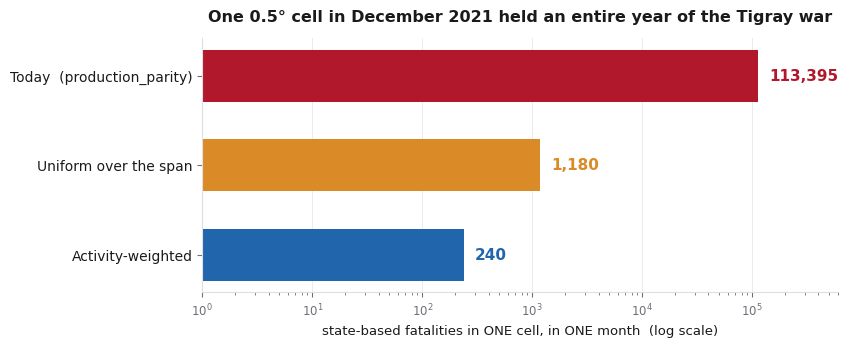

{'production_parity': '113,395', 'kgi_kti_distributed': '1,180', 'kgi_kti_activity': '240'}


In [7]:
"""Fig 1 -- state-based fatalities in cell 148759, December 2021."""

vals = {}
for k, d in cm.items():
    sel = d[(d.priogrid_gid == TIGRAY_CELL) & (d.date_month == TIGRAY_MONTH)]
    vals[k] = int(sel.best.sum())

fig, ax = plt.subplots(figsize=(8.2, 3.3))
ys = np.arange(len(PROFILES))[::-1]
for y, k in zip(ys, PROFILES):
    ax.barh(y, max(vals[k], 1), color=COLOR[k], height=0.58)
    ax.text(max(vals[k], 1) * 1.25, y, f"{vals[k]:,}", va="center",
            fontsize=11, fontweight="bold", color=COLOR[k])
ax.set_yticks(ys)
ax.set_yticklabels([LABEL[k] for k in PROFILES], fontsize=10, color=INK)
ax.set_xscale("log")
ax.set_xlim(1, 6e5)
ax.set_xlabel("state-based fatalities in ONE cell, in ONE month  (log scale)")
ax.set_title("One 0.5° cell in December 2021 held an entire year of the "
             "Tigray war", pad=12)
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
plt.show()

print({k: f"{v:,}" for k, v in vals.items()})

## 6. The map

The same month on the grid. Panel totals differ because deaths also move
*out* of December into the rest of 2021 &mdash; the mass leaves this frame as
well as this cell.

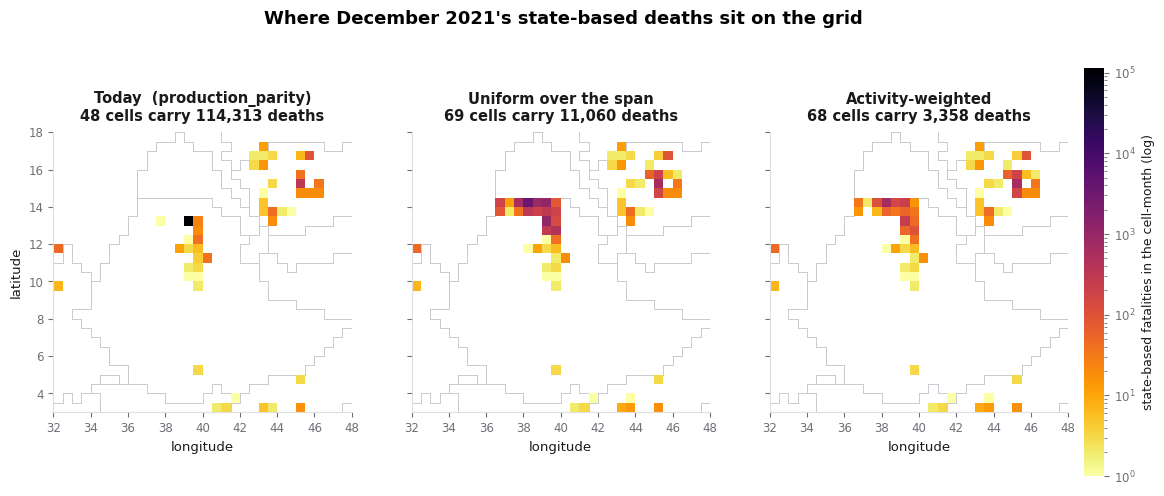

In [8]:
"""Fig 2 -- December 2021 state-based fatalities, Horn of Africa."""

LON_LO, LON_HI, LAT_LO, LAT_HI = 32.0, 48.0, 3.0, 18.0
segs = border_segments(LON_LO, LON_HI, LAT_LO, LAT_HI)

panels = {}
for k, d in cm.items():
    sel = d[d.date_month == TIGRAY_MONTH].copy()
    sel["lon"], sel["lat"] = cell_centre(sel.priogrid_gid.to_numpy())
    panels[k] = sel[(sel.lon.between(LON_LO, LON_HI))
                    & (sel.lat.between(LAT_LO, LAT_HI)) & (sel.best > 0)]

norm = LogNorm(vmin=1, vmax=max(p.best.max() for p in panels.values()))
cmap = plt.get_cmap("inferno_r")

fig, axes = plt.subplots(1, 3, figsize=(13.6, 5.3), sharex=True, sharey=True)
for ax, k in zip(axes, PROFILES):
    for x0, y0, x1, y1 in segs:
        ax.plot([x0, x1], [y0, y1], color="#C9C9D0", lw=0.7, zorder=1)
    p = panels[k]
    for v, lon, lat in zip(p.best, p.lon, p.lat):
        ax.add_patch(Rectangle((lon - 0.25, lat - 0.25), 0.5, 0.5,
                               facecolor=cmap(norm(v)), edgecolor="none", zorder=2))
    ax.set_title(f"{LABEL[k]}\n{len(p)} cells carry {int(p.best.sum()):,} deaths",
                 fontsize=10.5, pad=8)
    ax.set_xlim(LON_LO, LON_HI)
    ax.set_ylim(LAT_LO, LAT_HI)
    ax.set_aspect("equal")
    ax.set_xlabel("longitude")
axes[0].set_ylabel("latitude")

cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                  fraction=0.022, pad=0.015)
cb.set_label("state-based fatalities in the cell-month (log)", fontsize=9)
cb.outline.set_visible(False)
fig.suptitle("Where December 2021's state-based deaths sit on the grid",
             fontsize=13, fontweight="bold", y=0.99)
plt.show()

## 7. The series a model would be trained on

This is the plot that matters for forecasting. A model fitted to the red line
is being taught that a war arrives in one month and vanishes the next.

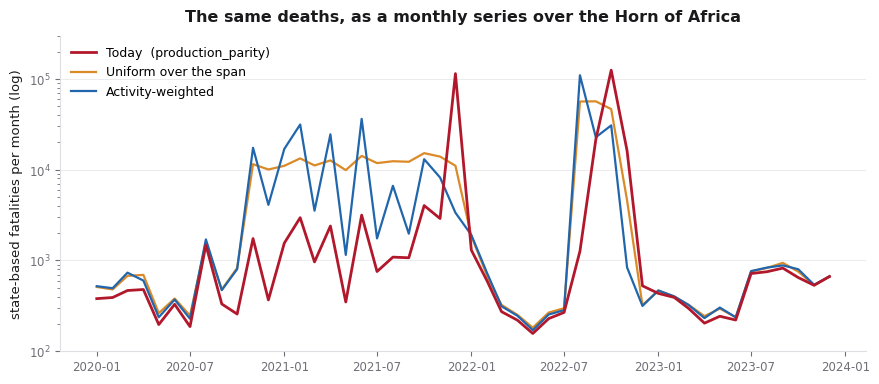

In [9]:
"""Fig 3 -- monthly state-based fatalities over the Horn of Africa."""

LO, HI = "2020-01-01", "2023-12-01"
idx = pd.date_range(LO, HI, freq="MS")

fig, ax = plt.subplots(figsize=(10.4, 4.1))
for k in PROFILES:
    d = sb[k]
    lon, lat = cell_centre(d.priogrid_gid.to_numpy())
    box = d[(lon >= 32) & (lon <= 48) & (lat >= 3) & (lat <= 18)]
    s = (box[box.date_month.between(LO, HI)].groupby("date_month").best.sum()
         .reindex(idx.strftime("%Y-%m-%d"), fill_value=0))
    ax.plot(idx, s.to_numpy(), color=COLOR[k], label=LABEL[k],
            lw=2.0 if k == "production_parity" else 1.6,
            zorder=3 if k == "production_parity" else 2)
ax.set_yscale("log")
ax.set_ylim(100, 3e5)
ax.set_ylabel("state-based fatalities per month (log)")
ax.set_title("The same deaths, as a monthly series over the Horn of Africa", pad=10)
ax.grid(axis="y", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
plt.show()

## 8. The whole dataset, not just Tigray

Ranking every state-based cell-month shows something the single-cell view
hides. **The head shrinks and the body lifts.** Conservation guarantees it:
the mass taken out of the top has to reappear further down. Checking only the
maximum would suggest the data got smaller. It did not.

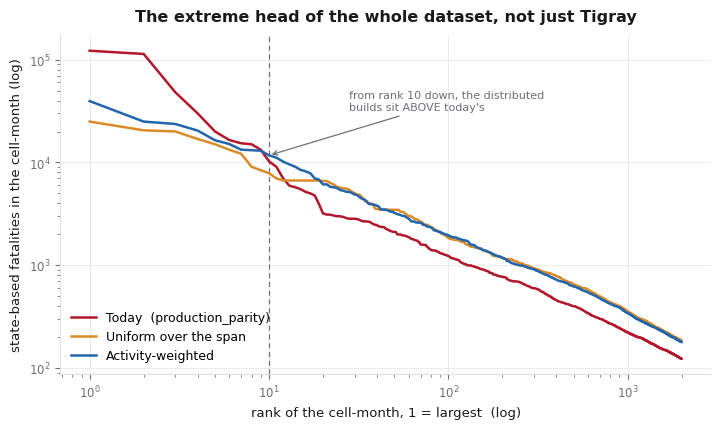

 rank      parity distributed    activity
    1     121,915      24,979      39,487
    2     113,395      20,545      24,979
    3      48,183      20,026      23,674
    4      30,000      16,918      20,429
    5      20,016      15,045      16,445
    6      16,539      13,315      15,129

crossover at rank 10


In [10]:
"""Fig 4 -- rank-size curve of every state-based cell-month."""

fig, ax = plt.subplots(figsize=(8.4, 4.4))
tops = {}
for k in PROFILES:
    v = np.sort(cm[k].best.to_numpy())[::-1][:2000]
    v = v[v > 0]
    tops[k] = v
    ax.plot(np.arange(1, len(v) + 1), v, color=COLOR[k], lw=1.8, label=LABEL[k])

cross = int(np.argmax(tops["production_parity"] < tops["kgi_kti_activity"])) + 1
ax.axvline(cross, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=1)
ax.annotate(f"from rank {cross} down, the distributed\nbuilds sit ABOVE today's",
            xy=(cross, tops["kgi_kti_activity"][cross - 1]), xytext=(28, 3.2e4),
            fontsize=8, color=MUTED,
            arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 0.9})
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("rank of the cell-month, 1 = largest  (log)")
ax.set_ylabel("state-based fatalities in the cell-month (log)")
ax.set_title("The extreme head of the whole dataset, not just Tigray", pad=10)
ax.grid(alpha=0.7)
ax.set_axisbelow(True)
ax.legend(loc="lower left")
plt.show()

print(f"{'rank':>5}" + "".join(f"{k.split('_')[-1]:>12}" for k in PROFILES))
for i in range(6):
    print(f"{i+1:>5}" + "".join(f"{tops[k][i]:>12,}" for k in PROFILES))
print(f"\ncrossover at rank {cross}")

## 9. Does it bite everywhere, or only where it should?

A redistribution that changed every month would be a different, worse bug.
This is the reassuring plot: the three lines mostly coincide.

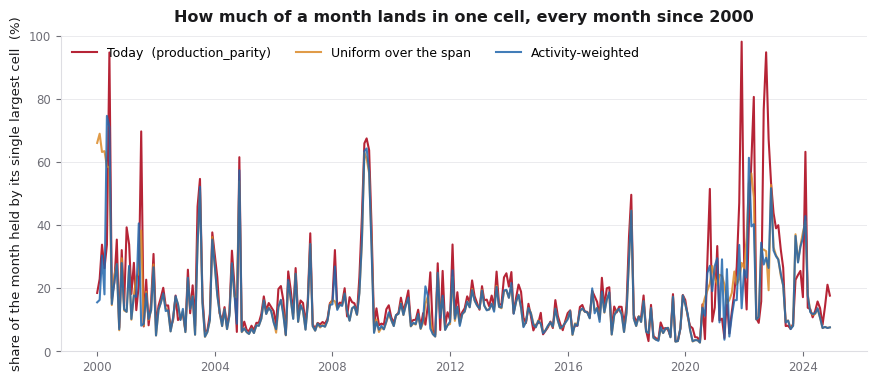

mean gap, today vs activity-weighted
    before 2020 : 2.91 points
    2020 onward : 10.70 points


In [11]:
"""Fig 5 -- share of each month held by its single largest cell."""

share = {}
for k in PROFILES:
    g = cm[k][cm[k].date_month.between("2000-01-01", "2024-12-01")].groupby("date_month").best
    share[k] = (g.max() / g.sum()).dropna() * 100

fig, ax = plt.subplots(figsize=(10.4, 4.1))
for k in PROFILES:
    s = share[k].sort_index()
    ax.plot(pd.to_datetime(s.index), s.to_numpy(), color=COLOR[k], lw=1.5,
            label=LABEL[k], alpha=0.95 if k == "production_parity" else 0.85)
ax.set_ylim(0, 100)
ax.set_ylabel("share of the month held by its single largest cell  (%)")
ax.set_title("How much of a month lands in one cell, every month since 2000", pad=10)
ax.grid(axis="y", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(loc="upper left", ncol=3)
plt.show()

gap = (share["production_parity"] - share["kgi_kti_activity"]).abs()
print(f"mean gap, today vs activity-weighted")
print(f"    before 2020 : {gap[gap.index < '2020-01-01'].mean():.2f} points")
print(f"    2020 onward : {gap[gap.index >= '2020-01-01'].mean():.2f} points")

## 10. The catalog

Every month since 1989 where today's build puts more than 70% of all
state-based fatalities on earth into one cell. Tigray is the worst of them,
not the only one.

Two rows carry the real argument:

- **Feb 1999: 91.8% &rarr; 89.2%.** Barely moves. That month genuinely was
  one place. The method leaves it alone.
- **Mar 1993: 80.6% &rarr; 12.5%.** The largest single correction in the
  dataset, and nothing to do with Ethiopia.

Being able to tell those two apart is better evidence that the weighting
works than any amount of peak reduction.

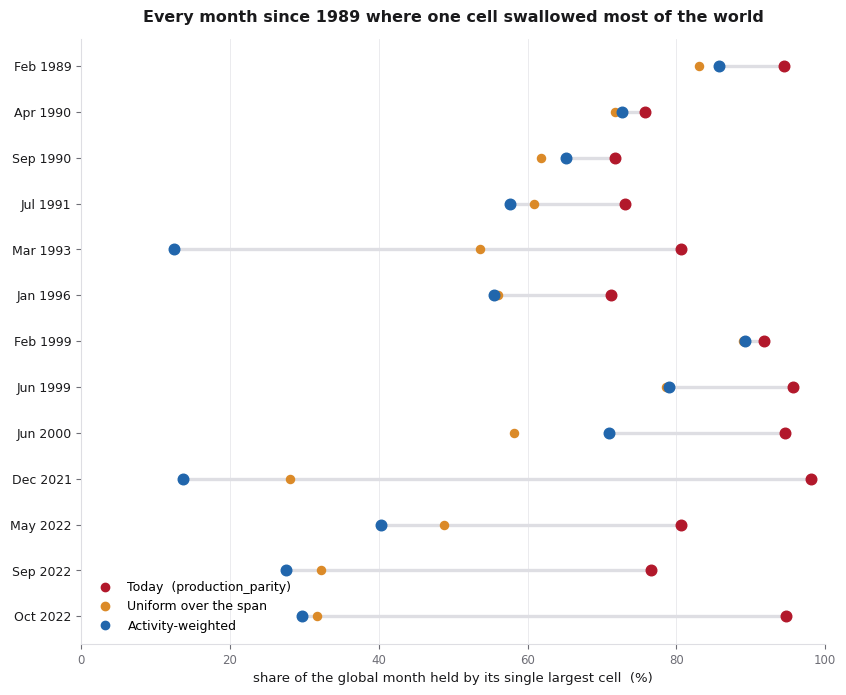

            production_parity  kgi_kti_distributed  kgi_kti_activity
date_month                                                          
1989-02-01               94.5                 83.0              85.7
1990-04-01               75.8                 71.7              72.7
1990-09-01               71.7                 61.8              65.1
1991-07-01               73.0                 60.8              57.6
1993-03-01               80.6                 53.6              12.5
1996-01-01               71.2                 56.0              55.4
1999-02-01               91.8                 88.9              89.2
1999-06-01               95.7                 78.6              79.0
2000-06-01               94.7                 58.2              71.0
2021-12-01               98.1                 28.0              13.6
2022-05-01               80.6                 48.8              40.2
2022-09-01               76.5                 32.2              27.5
2022-10-01               94.7     

In [12]:
"""Fig 6 -- the months where one cell swallowed most of the world."""

full = {}
for k in PROFILES:
    g = cm[k].groupby("date_month").best
    full[k] = (g.max() / g.sum()).dropna() * 100
sh = pd.DataFrame(full).sort_index()
bad = sh[sh.production_parity > 70]

fig, ax = plt.subplots(figsize=(9.6, 0.42 * len(bad) + 2.4))
ys = np.arange(len(bad))[::-1]
for y, (_, r) in zip(ys, bad.iterrows()):
    ax.plot([r.kgi_kti_activity, r.production_parity], [y, y],
            color=GRID, lw=2.4, solid_capstyle="round", zorder=1)
    for k, size in (("production_parity", 58), ("kgi_kti_distributed", 34),
                    ("kgi_kti_activity", 58)):
        ax.scatter(r[k], y, s=size, color=COLOR[k], zorder=3)
ax.set_yticks(ys)
ax.set_yticklabels([pd.Timestamp(i).strftime("%b %Y") for i in bad.index],
                   fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("share of the global month held by its single largest cell  (%)")
ax.set_title("Every month since 1989 where one cell swallowed most of the world",
             pad=12)
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COLOR[k],
                              label=LABEL[k]) for k in PROFILES],
          loc="lower left", labelspacing=0.5)
plt.show()

print(bad.round(1).to_string())

## 11. The caveat this notebook must not bury

Activity weighting does **not** reduce every peak. It moves mass toward
months with observed fighting, so an event's own largest cell-month can
*rise* even as the artefact cell falls. That is the mechanism working, but it
is not monotonic peak reduction, and anyone adopting this should know it
before they are surprised by it.

In [13]:
"""The Tigray event's own footprint, across the three builds."""

EVENT = 463131
print(f"{'profile':<24}{'rows':>8}{'cells':>8}{'months':>8}"
      f"{'own peak cell-month':>22}")
for k in PROFILES:
    d = raw[k][raw[k].id == EVENT]
    peak = d.groupby(["priogrid_gid", "date_month"]).best.sum().max()
    print(f"{k:<24}{len(d):>8,}{d.priogrid_gid.nunique():>8,}"
          f"{d.date_month.nunique():>8,}{int(peak):>22,}")

print("\nThe artefact cell falls 113,395 -> 240 while the event's own peak")
print("rises, because activity concentrates mass into months with fighting.")

profile                     rows   cells  months   own peak cell-month
production_parity              1       1       1               113,368
kgi_kti_distributed          216      18      12                 3,471
kgi_kti_activity             216      18      12                11,732

The artefact cell falls 113,395 -> 240 while the event's own peak
rises, because activity concentrates mass into months with fighting.


## 12. How to use any of this

```bash
uv run python scripts/build_viewpoint.py \
    --profile kgi_kti_activity \
    --output data/viewpoint/kgi_kti_activity.parquet
```

Nothing changes unless a profile is named. The pipeline
(`scripts/refresh_pipeline.sh`, step 3) invokes `production_parity`
explicitly, and `tests/test_adr049_profile_contract.py` pins both that the
default is unchanged and that the distributed profiles conserve mass.

Governance is ADR-049 (spatial) with its 2026-11-04 and 2026-11-05
amendments; the allocator itself is specified in
`reports/2026-11-04_summary_event_allocation_dossier/11_allocator_spec.md`.

### Known, open, and written down

- **Switching profile adds deaths, it does not only move them.** 43,933
  events carrying 785,626 fatalities (+22.6%) are dropped by production today
  and admitted by the new profiles. Any consumer comparing totals across a
  profile switch will see this before they see anything else.
- **`ceil_split` invents 96 deaths** across 74 events, live in production
  now. Small, but it is the current path reporting more than the source ever
  recorded. The apportioned profiles do not.
- `high < best` in **3,942 source events / 510,908 fatalities**, concentrated
  6&times; in the imprecisely-located class. Upstream UCDP, present in every
  store version.
- **Zero-activity months receive zero.** 1,760 events have a month with no
  observed activity inside their span. The assumption is pinned by a test so
  that changing it is a decision rather than an accident.
- `event_clarity` is **45.56%** of all fatality mass and is still used
  nowhere. It is what separates a real one-site massacre from an allocation
  artefact, which magnitude alone cannot do.